# 딥러닝 기초 5일차 실습과제: 전이학습과 최신 트렌드

## 과제 개요
이 과제에서는 **전이학습(Transfer Learning)**을 활용하여 의료 이미지를 분류하고, **Transformer**의 핵심 개념을 이해합니다.

### 사용 데이터셋
- **MedMNIST** (PathMNIST): 대장 조직 병리 이미지 (9 클래스)

### 학습 목표
1. 전이학습의 개념과 장점 이해
2. Feature Extraction vs Fine-tuning 비교
3. 사전학습 모델(ResNet) 활용
4. Transformer의 Self-Attention 개념 이해

### 예상 소요 시간
약 **1시간 30분**

---

> 📝 **작성자**: 조태희 · OZ 코딩 스쿨 AI 헬스케어 부트캠프 6기
>
> ▶️ **실행 방법 (Colab)**
> 1. `런타임 → 런타임 유형 변경 → T4 GPU`를 선택합니다.
> 2. `런타임 → 모두 실행`. 처음 실행할 때 PathMNIST 데이터와 ImageNet 사전학습 가중치(ResNet18)를 자동으로 내려받습니다.
> 3. ⏱️ Part 0의 **`QUICK_MODE=True`**(기본값)는 학습 20,000장 / 검증 4,000장만 사용해 학습 시간을 줄입니다. 시간이 충분하면 `False`로 바꿔 전체 데이터로 학습해도 됩니다.
>
> 📊 Part 3(Self-Attention)은 데이터·GPU 없이도 바로 실행됩니다. Part 1~2의 비교 결과 숫자는 실행 후 결과 비교 셀의 출력으로 확인합니다.

## Part 0: 환경 설정

In [1]:
# 필요한 라이브러리 import
import torch                                         # 파이토치 본체
import torch.nn as nn                                # 층·손실 함수
import torch.optim as optim                          # 옵티마이저
from torch.utils.data import DataLoader              # 배치 공급기
from torchvision import transforms, models           # 이미지 변환, 사전학습 모델

import numpy as np                                   # 수치 계산
import matplotlib.pyplot as plt                      # 그래프
from sklearn.metrics import accuracy_score, classification_report  # 평가 지표

# 재현성
torch.manual_seed(42)                                # 파이토치 난수 고정
np.random.seed(42)                                   # numpy 난수 고정

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')  # GPU가 있으면 사용
print(f'Using device: {device}')

# MedMNIST 설치
!pip install medmnist -q

# [추가] Part 3 그래프의 한글 축 이름이 네모(□)로 깨지지 않도록 한글 폰트 설정
try:
    import koreanize_matplotlib                      # 설치돼 있으면 불러오기만 해도 나눔고딕 폰트 적용
except ImportError:                                  # Colab에는 기본으로 없으므로
    !pip install koreanize-matplotlib -q
    import koreanize_matplotlib

Using device: cpu


In [2]:
# MedMNIST 데이터셋 로드
import medmnist                                      # 의료 이미지 벤치마크 패키지
from medmnist import INFO                            # 데이터셋별 정보 사전

# PathMNIST: 대장 조직 병리 이미지
data_flag = 'pathmnist'
info = INFO[data_flag]                               # pathmnist 정보
DataClass = getattr(medmnist, info['python_class'])  # 'PathMNIST' 문자열 → 데이터셋 클래스

NUM_CLASSES = len(info['label'])                     # 클래스 수
CLASS_NAMES = list(info['label'].values())           # 클래스 이름 목록

print(f"데이터셋: {data_flag}")
print(f"클래스 수: {NUM_CLASSES}")
print(f"클래스: {CLASS_NAMES}")
print(f"샘플 수: {info['n_samples']}")               # [추가] train/val/test 이미지 수

데이터셋: pathmnist
클래스 수: 9
클래스: ['adipose', 'background', 'debris', 'lymphocytes', 'mucus', 'smooth muscle', 'normal colon mucosa', 'cancer-associated stroma', 'colorectal adenocarcinoma epithelium']
샘플 수: {'train': 89996, 'val': 10004, 'test': 7180}


⏱️ **[추가] 빠른 실습 모드(QUICK_MODE)**: 28×28 이미지를 224×224로 키우면 장당 계산량이 (224/28)² = 64배가 됩니다. 기본값으로는 학습 20,000장 / 검증 4,000장만 무작위로(시드 고정) 뽑아 학습 시간을 줄입니다. `False`로 바꾸면 템플릿과 같이 전체 데이터를 사용합니다.

In [ ]:
# 데이터 변환 정의
IMAGENET_MEAN = [0.485, 0.456, 0.406]                # ImageNet RGB 평균 (사전학습 모델의 입력 분포에 맞춤)
IMAGENET_STD = [0.229, 0.224, 0.225]                 # ImageNet RGB 표준편차

def to_rgb(x):
    """1채널 -> 3채널 변환"""
    return x.repeat(3, 1, 1) if x.shape[0] == 1 else x   # 흑백이면 3번 복사, 컬러면 그대로

train_transform = transforms.Compose([
    transforms.ToTensor(),                           # PIL → 텐서 [C, 28, 28], 값 0~1
    transforms.Lambda(to_rgb),                       # 3채널 보장
    transforms.Resize((224, 224)),                   # ResNet 입력 크기로 확대
    transforms.RandomHorizontalFlip(),               # 50% 확률 좌우 반전 (증강)
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)  # 채널별 정규화
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(to_rgb),
    transforms.Resize((224, 224)),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)  # 증강 없이 크기·정규화만
])

# 데이터셋 로드
train_dataset = DataClass(split='train', transform=train_transform, download=True)  # 처음 실행 시 다운로드
val_dataset = DataClass(split='val', transform=test_transform, download=True)
test_dataset = DataClass(split='test', transform=test_transform, download=True)

# ⏱️ [추가] 빠른 실습 모드
QUICK_MODE = True                                    # False로 바꾸면 전체 데이터 사용
if QUICK_MODE:
    from torch.utils.data import Subset              # 일부 인덱스만 골라 쓰는 도구
    g = torch.Generator().manual_seed(42)            # 항상 같은 이미지가 뽑히도록 고정
    train_idx = torch.randperm(len(train_dataset), generator=g)[:min(20000, len(train_dataset))]  # 학습 20,000장
    val_idx = torch.randperm(len(val_dataset), generator=g)[:min(4000, len(val_dataset))]          # 검증 4,000장
    train_dataset = Subset(train_dataset, train_idx.tolist())   # 부분집합으로 교체
    val_dataset = Subset(val_dataset, val_idx.tolist())

# DataLoader (빠른 실험을 위해 작은 배치)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)   # 학습: 섞어서 32장씩
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)      # 검증: 순서대로
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)    # 테스트: 순서대로

print(f"\nTrain: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}")

In [ ]:
# 샘플 이미지 확인
images, labels = next(iter(train_loader))            # 첫 배치 꺼내기

fig, axes = plt.subplots(2, 4, figsize=(12, 6))      # 8칸
for i, ax in enumerate(axes.flat):
    img = images[i].numpy().transpose(1, 2, 0)       # [C, H, W] → [H, W, C]
    img = img * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)  # 정규화 되돌리기
    img = np.clip(img, 0, 1)                         # 0~1 범위로 자르기
    ax.imshow(img)                                   # 이 칸(ax)에 직접 그리기
    ax.set_title(CLASS_NAMES[labels[i].item()])      # 라벨 번호 → 클래스 이름
    ax.axis('off')
plt.suptitle('Sample Training Images', fontsize=14)
plt.tight_layout()
plt.show()

---

## Part 1: 전이학습 - Feature Extraction

**Feature Extraction**은 사전학습된 모델의 가중치를 **동결**하고, 마지막 분류기만 학습합니다.

- 장점: 빠른 학습, 적은 데이터로도 가능
- 단점: 도메인이 많이 다르면 성능 제한

In [ ]:
# ============================================
# Feature Extraction 모델
# ============================================

def create_feature_extractor(num_classes):
    """
    사전학습된 ResNet18을 Feature Extractor로 사용
    - 모든 레이어 동결
    - 마지막 FC만 학습
    """
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)  # ImageNet 사전학습 가중치 (처음엔 다운로드)

    # 모든 파라미터 동결
    for param in model.parameters():
        param.requires_grad = False                  # 기울기 계산 안 함 → 업데이트되지 않음

    # 마지막 FC 레이어만 교체 (이 부분만 학습)
    model.fc = nn.Sequential(
        nn.Dropout(0.5),                             # 과적합 방지
        nn.Linear(model.fc.in_features, num_classes) # 512 → 9 (새 층은 기본적으로 학습 가능)
    )

    return model

# 모델 생성
fe_model = create_feature_extractor(NUM_CLASSES)

# 학습 가능한 파라미터 확인
trainable = sum(p.numel() for p in fe_model.parameters() if p.requires_grad)  # 학습 가능
total = sum(p.numel() for p in fe_model.parameters())                         # 전체
print(f"Feature Extractor:")
print(f"  학습 가능: {trainable:,} / 전체: {total:,} ({trainable/total*100:.2f}%)")

In [ ]:
# ============================================
# 학습 함수
# ============================================

def train_model(model, train_loader, val_loader, num_epochs=10, lr=0.001, device='cpu'):
    """
    간단한 학습 함수
    """
    model = model.to(device)                         # 모델을 GPU/CPU로
    criterion = nn.CrossEntropyLoss()                # 다중 분류 손실
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)  # 학습 가능한 파라미터만 옵티마이저에 전달

    history = {'train_acc': [], 'val_acc': []}       # 에폭별 정확도 기록

    for epoch in range(num_epochs):
        # Train
        model.train()                                # 학습 모드
        correct, total = 0, 0
        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.squeeze().long().to(device)  # [N, 1] → [N], 정수형

            optimizer.zero_grad()                    # 기울기 초기화
            outputs = model(images)                  # 순전파
            loss = criterion(outputs, labels)        # 손실
            loss.backward()                          # 역전파
            optimizer.step()                         # 업데이트

            _, predicted = outputs.max(1)            # 예측 클래스
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

        train_acc = correct / total                  # 학습 정확도

        # Validate
        model.eval()                                 # 평가 모드
        correct, total = 0, 0
        with torch.no_grad():                        # 기울기 끄기
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.squeeze().long().to(device)
                outputs = model(images)
                _, predicted = outputs.max(1)
                total += labels.size(0)
                correct += predicted.eq(labels).sum().item()

        val_acc = correct / total                    # 검증 정확도

        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)

        print(f"Epoch [{epoch+1}/{num_epochs}] Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f}")

    return model, history

In [ ]:
# Feature Extraction 학습
print("=" * 50)
print("Feature Extraction 학습")
print("=" * 50)

torch.manual_seed(42)                                # [추가] 재현성
fe_model = create_feature_extractor(NUM_CLASSES)     # 새 모델
fe_model, fe_history = train_model(fe_model, train_loader, val_loader,
                                    num_epochs=5, lr=0.001, device=device)   # 5에폭, 학습률 0.001

---

## Part 2: 전이학습 - Fine-tuning

**Fine-tuning**은 사전학습된 모델의 일부 레이어도 함께 학습합니다.

- 장점: 더 높은 성능 가능
- 주의: 더 많은 데이터와 시간 필요, 과적합 위험

In [ ]:
# ============================================
# Fine-tuning 모델
# ============================================

def create_finetuning_model(num_classes):
    """
    ResNet18의 마지막 블록(layer4)과 FC를 함께 학습
    """
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

    # 모든 파라미터 동결
    for param in model.parameters():
        param.requires_grad = False

    # layer4 동결 해제 (Fine-tuning)
    for param in model.layer4.parameters():
        param.requires_grad = True                   # 마지막 블록은 새 데이터에 맞게 조정

    # FC 레이어 교체
    model.fc = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(model.fc.in_features, num_classes)
    )

    return model

# 모델 생성
ft_model = create_finetuning_model(NUM_CLASSES)

trainable = sum(p.numel() for p in ft_model.parameters() if p.requires_grad)
total = sum(p.numel() for p in ft_model.parameters())
print(f"Fine-tuning:")
print(f"  학습 가능: {trainable:,} / 전체: {total:,} ({trainable/total*100:.2f}%)")

#### 📐 [추가] 학습 가능한 파라미터 수 분해 (가중치 다운로드 없이)

파라미터 **개수**는 가중치 값과 상관없이 **구조**로만 정해지므로, `weights=None`으로 같은 구조를 만들어 세어도 위 셀들과 같은 숫자가 나옵니다. 과제 2-1의 1번 답의 근거입니다.

In [3]:
def count_params(model):
    """(학습 가능한 파라미터 수, 전체 파라미터 수)"""
    return (sum(p.numel() for p in model.parameters() if p.requires_grad),
            sum(p.numel() for p in model.parameters()))

def resnet18_head(num_classes, unfreeze_layer4):
    """위 두 함수와 같은 구조를 가중치 다운로드 없이 생성"""
    m = models.resnet18(weights=None)                # 구조만 생성
    for p in m.parameters():
        p.requires_grad = False                      # 전부 동결
    if unfreeze_layer4:                              # Fine-tuning이면
        for p in m.layer4.parameters():
            p.requires_grad = True                   # layer4 동결 해제
    m.fc = nn.Sequential(nn.Dropout(0.5), nn.Linear(m.fc.in_features, num_classes))  # 새 분류기
    return m

fe_t, fe_all = count_params(resnet18_head(NUM_CLASSES, False))   # Feature Extraction 구조
ft_t, ft_all = count_params(resnet18_head(NUM_CLASSES, True))    # Fine-tuning 구조
print(f"Feature Extraction 학습 가능: {fe_t:>10,} / 전체 {fe_all:,} ({fe_t / fe_all * 100:.2f}%)")
print(f"Fine-tuning        학습 가능: {ft_t:>10,} / 전체 {ft_all:,} ({ft_t / ft_all * 100:.2f}%)")
print(f"차이: {ft_t - fe_t:,}개 (= layer4 블록의 파라미터 수), 약 {ft_t / fe_t:,.0f}배")

Feature Extraction 학습 가능:      4,617 / 전체 11,181,129 (0.04%)
Fine-tuning        학습 가능:  8,398,345 / 전체 11,181,129 (75.11%)
차이: 8,393,728개 (= layer4 블록의 파라미터 수), 약 1,819배


In [ ]:
# Fine-tuning 학습
print("=" * 50)
print("Fine-tuning 학습")
print("=" * 50)

torch.manual_seed(42)                                # [추가] 재현성
ft_model = create_finetuning_model(NUM_CLASSES)      # 새 모델
ft_model, ft_history = train_model(ft_model, train_loader, val_loader,
                                    num_epochs=5, lr=0.0001, device=device)  # 사전학습 층까지 건드리므로 작은 학습률(0.0001)

In [ ]:
# 결과 비교
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(fe_history['val_acc'], label='Feature Extraction', marker='o', color='#8FBC8F')  # FE 검증 정확도
ax.plot(ft_history['val_acc'], label='Fine-tuning', marker='s', color='#87CEEB')         # FT 검증 정확도
ax.set_title('Validation Accuracy Comparison')
ax.set_xlabel('Epoch')
ax.set_ylabel('Accuracy')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\n최종 Val Accuracy:")
print(f"  Feature Extraction: {fe_history['val_acc'][-1]:.4f}")
print(f"  Fine-tuning: {ft_history['val_acc'][-1]:.4f}")
print(f"  차이 (Fine-tuning − Feature Extraction): {ft_history['val_acc'][-1] - fe_history['val_acc'][-1]:+.4f}")  # [추가]

### [필수] 과제 2-1: 전이학습 비교 분석

1. Feature Extraction과 Fine-tuning의 학습 가능한 파라미터 수 차이는?
   - 답변: Feature Extraction은 새 분류기(fc: 512×9 + 9)만 학습하므로 **4,617개**(전체 11,181,129개의 **0.04%**)이고, Fine-tuning은 여기에 마지막 블록 `layer4`까지 풀어서 **8,398,345개**(**75.11%**)를 학습합니다. 차이는 정확히 layer4의 파라미터 수인 **8,393,728개**이고, 배수로는 약 **1,819배**입니다(위 '파라미터 수 분해' 셀 출력 기준). 학습할 양이 많은 만큼 Fine-tuning은 역전파를 layer4까지 해야 해서 에폭당 시간과 GPU 메모리가 더 듭니다. 실제 정확도 차이는 위 결과 비교 셀의 `차이 (Fine-tuning − Feature Extraction)` 출력으로 확인합니다.

2. 어떤 상황에서 Feature Extraction이 더 적합할까요?
   - 답변:
     - ① **데이터가 적을 때**(수백~수천 장): 학습할 파라미터가 4,617개뿐이라 과적합 위험이 낮습니다.
     - ② **새 데이터가 사전학습 데이터(ImageNet 일상 사진)와 비슷할 때**: 이미 배운 특징이 그대로 잘 통합니다.
     - ③ **GPU·시간이 부족하거나 빠른 베이스라인이 필요할 때**: 역전파가 분류기에서 멈추므로 빠르고 가볍습니다.
     - 반대로 이번 PathMNIST처럼 데이터가 많고(학습 89,996장, 위 데이터셋 정보 출력) ImageNet과 도메인이 다른 의료 영상이면 Fine-tuning이 더 유리한 경우가 많습니다.
   - 💡 비유: Feature Extraction은 이미 숙련된 사진작가의 '보는 눈'을 그대로 빌려 쓰는 것이라, 새로 배울 게 적을 때(비슷한 사진, 적은 예시) 가장 효율적입니다.

---

## Part 3: Transformer와 Self-Attention 이해

Transformer는 현대 AI의 핵심 아키텍처입니다. 핵심 개념인 **Self-Attention**을 이해해봅시다.

In [4]:
# ============================================
# Self-Attention 시각화
# ============================================

def simple_self_attention(query, key, value):
    """
    간단한 Self-Attention 구현

    Attention(Q, K, V) = softmax(QK^T / sqrt(d_k)) * V
    """
    d_k = query.shape[-1]                            # 임베딩 차원 수 (여기서는 4)

    # 1. Query와 Key의 유사도 계산
    scores = torch.matmul(query, key.transpose(-2, -1)) / np.sqrt(d_k)  # 모든 토큰 쌍의 내적(유사도) / √d_k (값이 너무 커지지 않게)

    # 2. Softmax로 확률화 (Attention Weights)
    attention_weights = torch.softmax(scores, dim=-1)   # 각 행(현재 토큰)마다 합이 1인 '관심도'로 변환

    # 3. Value에 가중치 적용
    output = torch.matmul(attention_weights, value)     # 관심도만큼 다른 토큰 정보를 섞은 가중 평균

    return output, attention_weights

# 예시: 문장 "I love AI" (3개 토큰, 4차원 임베딩)
torch.manual_seed(42)                                # 같은 임베딩이 나오도록 고정
seq_len, d_model = 3, 4                              # 토큰 3개, 각 토큰은 4개 숫자로 표현
tokens = ['I', 'love', 'AI']

# 임베딩 벡터 (실제로는 학습됨)
embeddings = torch.randn(1, seq_len, d_model)        # [배치 1, 토큰 3, 차원 4]

# Self-Attention: Q=K=V 모두 같은 입력 사용
output, attention = simple_self_attention(embeddings, embeddings, embeddings)  # 실제 Transformer는 Q, K, V를 각각 다른 Linear 층으로 만듦

print("입력 임베딩 shape:", embeddings.shape)
print("출력 shape:", output.shape)                   # 입력과 같은 모양 → 각 토큰이 '문맥이 섞인' 새 벡터가 됨
print("\nAttention Weights (각 토큰이 다른 토큰에 주는 관심도):")
print(attention[0].numpy().round(3))                 # 3x3 표, 각 행의 합 = 1
print("각 행의 합:", attention[0].sum(dim=-1).numpy().round(3))  # [추가] softmax 결과라 행마다 합이 1인지 확인
print("토큰별 임베딩 크기(노름):", embeddings[0].norm(dim=-1).numpy().round(3))  # [추가] 결과 해석용: 자기 자신과의 내적 = 노름의 제곱
print("유사도 점수(QKᵀ/√d_k):\n", (embeddings[0] @ embeddings[0].T / np.sqrt(d_model)).numpy().round(3))  # [추가] softmax 전 점수

입력 임베딩 shape: torch.Size([1, 3, 4])
출력 shape: torch.Size([1, 3, 4])

Attention Weights (각 토큰이 다른 토큰에 주는 관심도):
[[0.332 0.29  0.378]
 [0.034 0.93  0.036]
 [0.307 0.251 0.442]]
각 행의 합: [1. 1. 1.]
토큰별 임베딩 크기(노름): [0.488 2.565 1.107]
유사도 점수(QKᵀ/√d_k):
 [[ 0.119 -0.016  0.251]
 [-0.016  3.289  0.048]
 [ 0.251  0.048  0.613]]


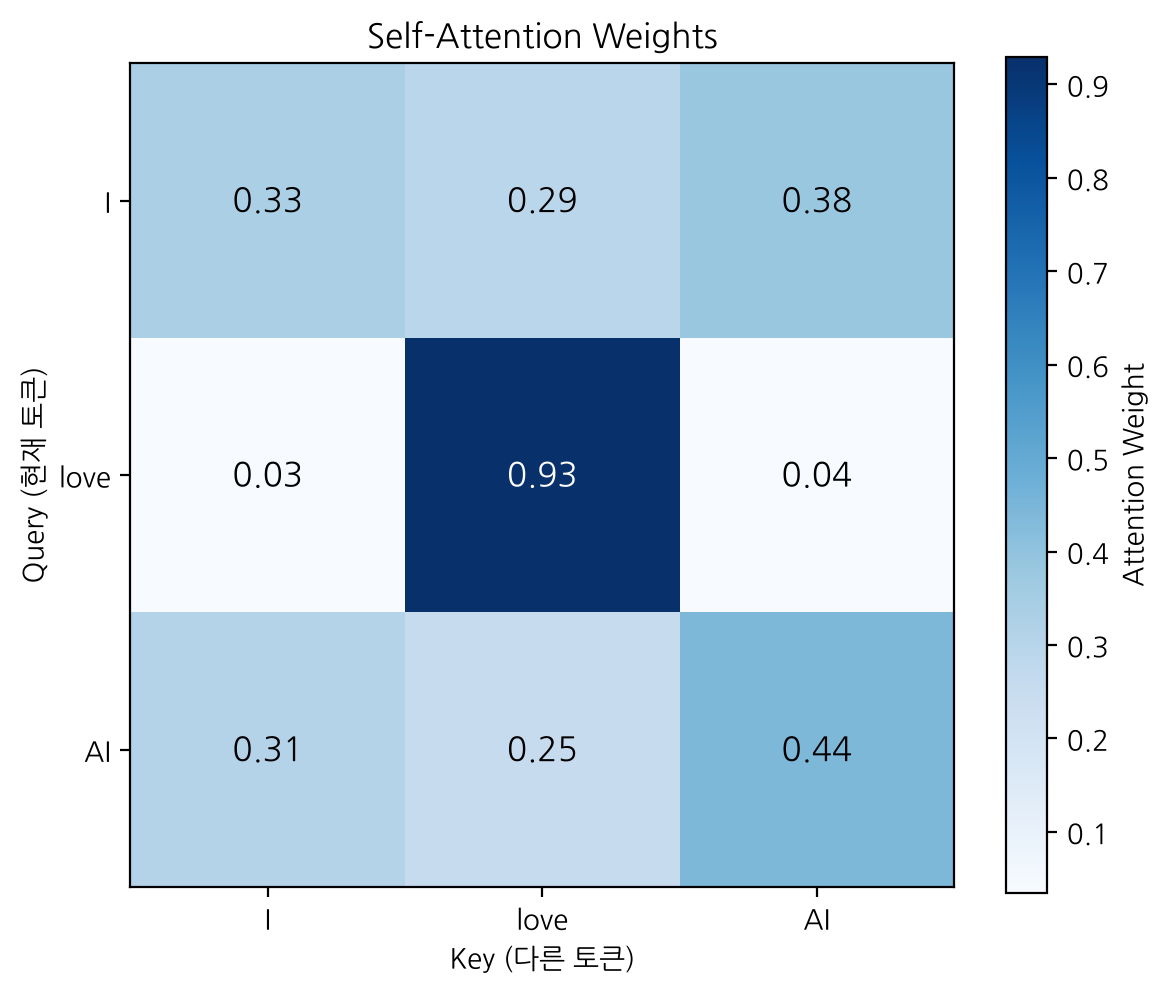


해석: 각 행은 해당 토큰이 다른 토큰들에 얼마나 '관심'을 주는지를 보여줍니다.


In [5]:
# Attention 시각화
plt.figure(figsize=(6, 5))
plt.imshow(attention[0].numpy(), cmap='Blues')       # 3x3 관심도 행렬을 색으로 표시 (진할수록 관심 큼)
plt.colorbar(label='Attention Weight')
plt.xticks(range(seq_len), tokens)                   # 가로축: Key (참고 대상 토큰)
plt.yticks(range(seq_len), tokens)                   # 세로축: Query (지금 처리 중인 토큰)
plt.xlabel('Key (다른 토큰)')
plt.ylabel('Query (현재 토큰)')
plt.title('Self-Attention Weights')

# 값 표시
for i in range(seq_len):                             # 행
    for j in range(seq_len):                         # 열
        plt.text(j, i, f'{attention[0, i, j]:.2f}', ha='center', va='center', fontsize=12,
                 color='white' if attention[0, i, j] > 0.6 else 'black')  # 칸마다 숫자 표시 ([수정] 진한 칸은 흰 글씨로 → 잘 보이게)

plt.tight_layout()
plt.show()

print("\n해석: 각 행은 해당 토큰이 다른 토큰들에 얼마나 '관심'을 주는지를 보여줍니다.")

#### 🔍 결과 읽기

- 각 행은 softmax 결과라서 **합이 1**입니다(예: 'I' 행 0.332 + 0.29 + 0.378 = 1).
- **'love'** 행은 자기 자신에게 **0.93**의 관심을 줍니다. 'love' 임베딩의 크기(노름)가 2.565로 가장 커서, 자기 자신과의 내적(= 노름의 제곱)을 √4로 나눈 점수가 **3.289**로 다른 점수(−0.016, 0.048)보다 훨씬 크고, softmax가 이 차이를 지수(exp)로 더 키우기 때문입니다.
- 반대로 **'I'**는 노름이 0.488로 작아 점수끼리 차이가 작으므로(0.119, −0.016, 0.251) 관심이 0.29~0.378로 고르게 퍼졌고, 자기 자신보다 'AI'(0.378)를 가장 많이 참고했습니다.
- ⚠️ 주의: 여기서는 Q=K=V에 **같은 무작위 임베딩**을 그대로 넣었기 때문에, 이 숫자에 '주어·동사' 같은 언어적 의미는 없습니다. 실제 Transformer는 Q, K, V를 각각 **학습되는 서로 다른 Linear 층**(W_Q, W_K, W_V)으로 만들어서, 학습을 거치며 "동사는 주어와 목적어를 참고한다" 같은 의미 있는 관심 패턴이 생깁니다.

### Transformer 핵심 개념 정리

| 개념 | 설명 |
|------|------|
| **Self-Attention** | 문장 내 모든 단어가 서로를 참조 |
| **Multi-Head** | 여러 관점에서 Attention 계산 |
| **Positional Encoding** | 순서 정보 추가 (RNN 없이!) |
| **BERT** | 양방향 이해 (빈칸 채우기 학습) |
| **GPT** | 단방향 생성 (다음 단어 예측) |

### [필수] 과제 3-1: Transformer 이해도 점검

1. Self-Attention이 RNN보다 좋은 점은 무엇인가요?
   - 답변:
     - ① **병렬 처리**: RNN은 단어를 앞에서부터 하나씩 차례로 처리해야 해서(앞 단어 계산이 끝나야 다음 단어) 느리지만, Self-Attention은 모든 단어 쌍의 관련도를 행렬 곱 한 번(`QKᵀ`)으로 동시에 계산하므로 GPU로 한꺼번에 처리할 수 있습니다.
     - ② **먼 단어 사이의 관계(장거리 의존성)**: RNN은 멀리 떨어진 단어의 정보가 여러 단계를 거치며 희미해지지만(기울기 소실), Self-Attention은 모든 단어가 서로 **한 단계 만에 직접** 연결되어 문장이 길어도 앞뒤 관계를 잘 잡습니다.
     - ③ **들여다볼 수 있음**: 위 히트맵처럼 어떤 단어가 어떤 단어를 참고했는지 attention 가중치로 확인할 수 있습니다.
     - (대신 문장 길이가 n이면 계산량이 n²으로 늘어나는 비용이 있습니다.)
   - 💡 비유: RNN은 '귓속말 전달 게임'(한 명씩 차례로 전달해서 끝으로 갈수록 내용이 흐려짐), Self-Attention은 '단체 대화방'(모두가 모든 메시지를 한 번에 봄)입니다.

2. BERT와 GPT의 가장 큰 차이점은?
   - 답변: 가장 큰 차이는 **문맥을 보는 방향과 사전학습 목표**입니다.
     - **BERT**: Transformer의 **인코더**만 사용하고, 문장의 **앞뒤 문맥을 모두(양방향)** 보면서 가려진 단어를 맞히는 **빈칸 채우기**(Masked Language Model)로 학습합니다 → 문장 **이해**(분류, 개체명 인식, 질의응답)에 강합니다.
     - **GPT**: Transformer의 **디코더**만 사용하고, **앞쪽 단어만(단방향, 왼쪽→오른쪽)** 보면서 **다음 단어 예측**으로 학습합니다 → 문장 **생성**(대화, 글쓰기, 요약)에 강합니다.
   - 💡 비유: BERT는 앞뒤를 다 읽고 빈칸을 채우는 독해 시험, GPT는 앞 내용만 보고 다음 문장을 이어 쓰는 작문 시험입니다.

---

## Part 4: [도전] HuggingFace로 감성 분석

실제 사전학습된 Transformer 모델을 사용해봅시다.

In [ ]:
# [도전 과제] HuggingFace Transformers 사용해보기
# 아래 코드를 실행하고 다른 문장으로도 테스트해보세요!
# (Colab에는 transformers가 기본 설치되어 있고, 처음 실행 시 영어 감성 분석 모델을 자동으로 내려받습니다)

try:
    from transformers import pipeline                # '모델 불러오기 + 전처리 + 예측'을 한 번에 해 주는 도구

    # 감성 분석 파이프라인
    sentiment = pipeline('sentiment-analysis')       # 모델을 지정하지 않으면 영어 기본 모델(DistilBERT SST-2)을 사용 (안내 경고가 뜰 수 있음)

    # 테스트 문장들
    texts = [
        "I love learning deep learning!",
        "This is really difficult and frustrating.",
        "The medical AI can save many lives.",
        "The doctor explained the side effects very kindly.",      # [추가] 의료 상황 문장 (긍정 예상)
        "I waited three hours and nobody told me anything.",       # [추가] 의료 상황 문장 (부정 예상)
    ]

    print("감성 분석 결과:")
    print("=" * 50)
    for text in texts:                               # 문장마다
        result = sentiment(text)[0]                  # 예측 결과: {'label': POSITIVE/NEGATIVE, 'score': 확신도}
        print(f"입력: {text}")
        print(f"결과: {result['label']} (신뢰도: {result['score']:.4f})")
        print()

except ImportError:                                  # transformers가 설치되지 않은 환경
    print("transformers 라이브러리가 필요합니다.")
    print("설치: !pip install transformers")
except Exception as e:                               # [추가] 인터넷 문제 등으로 모델을 내려받지 못한 경우
    print("모델을 불러오지 못했습니다:", type(e).__name__, e)

> 참고: 이 기본 모델은 **영어 문장으로만** 학습되어 한국어 문장에는 맞지 않습니다. 한국어 감성 분석이 필요하면 한국어로 학습된 모델(예: KoBERT·KoELECTRA 계열을 감성 데이터로 미세조정한 모델)을 `pipeline('sentiment-analysis', model='모델 이름')`으로 지정해야 합니다.

---

## 5일차 학습 정리 체크리스트

- [x] **전이학습**: 사전학습된 모델을 새 작업에 활용
- [x] **Feature Extraction**: 가중치 동결, 분류기만 학습 (빠름)
- [x] **Fine-tuning**: 일부 레이어도 함께 학습 (고성능)
- [x] **Self-Attention**: 문장 내 모든 위치가 서로 참조
- [x] **Transformer**: Attention만으로 구성, 병렬 처리 가능
- [x] **BERT/GPT**: 대표적인 사전학습 언어 모델

---

## 수고하셨습니다! 🎉

5일간의 딥러닝 기초 과정을 모두 완료했습니다!

### 제출 전 체크리스트
- [x] 과제 2-1 (전이학습 비교) 답변 작성
- [x] 과제 3-1 (Transformer 이해) 답변 작성
- [x] [선택] 도전 과제 (HuggingFace 실행)

## 📌 핵심 정리

- **전이학습** = 큰 데이터(ImageNet)로 미리 학습한 모델의 '보는 눈'을 새 문제에 재사용하는 것입니다. **Feature Extraction**은 분류기만(4,617개, 0.04%), **Fine-tuning**은 layer4까지(8,398,345개, 75.11%) 학습하며, Fine-tuning에는 사전학습 지식을 망가뜨리지 않도록 더 작은 학습률(여기서는 0.0001)을 씁니다.
- 어느 쪽이 나은지는 데이터 양·도메인 차이·자원에 따라 달라지므로, 결과 비교 셀의 `차이` 출력처럼 **직접 실험해서 확인**합니다.
- **Self-Attention** = `softmax(QKᵀ / √d_k) · V`: 각 토큰이 모든 토큰과의 유사도(내적)를 계산하고, 그 비율대로 정보를 섞어 문맥이 반영된 새 표현을 만듭니다. √d_k로 나누는 이유는 차원이 커질수록 내적 값이 커져 softmax가 한 토큰으로 과하게 쏠리는 것(위 'love' 행처럼)을 줄이기 위해서입니다.
- **Transformer**는 RNN 없이 Attention으로 모든 위치를 한 번에 처리해 병렬화와 장거리 관계에 강하고, **BERT**(인코더·양방향·이해)와 **GPT**(디코더·단방향·생성)가 대표적인 사전학습 언어 모델입니다.